In [3]:
import keras
from keras.applications.resnet50 import ResNet50
from keras.applications.resnet50 import preprocess_input, decode_predictions
import numpy as np
import matplotlib.pyplot as plt

model = ResNet50(weights='imagenet')

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Predicted: [('n01882714', 'koala', np.float32(0.9991135)), ('n13054560', 'bolete', np.float32(0.00046200253)), ('n01873310', 'platypus', np.float32(0.00015017361))]


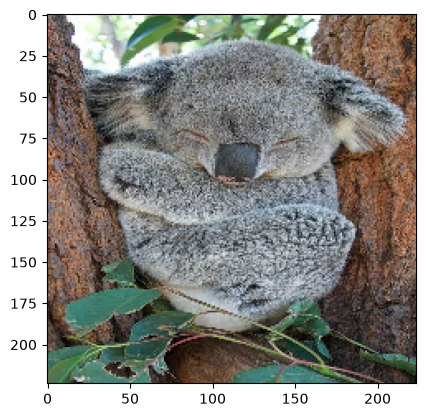

In [6]:


img_path = 'img/koala.jpeg' #source:https://en.wikipedia.org/wiki/Elephant
img = keras.utils.load_img(img_path, target_size=(224, 224))
plt.imshow(img)  
x = keras.utils.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

preds = model.predict(x)

print('Predicted:', decode_predictions(preds, top=3)[0])


/Volumes/Sirch/Machine Learning/Machine_Learning_and_Data_Science/03-exercises-and-practice/.venv/lib/python3.14/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_177']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


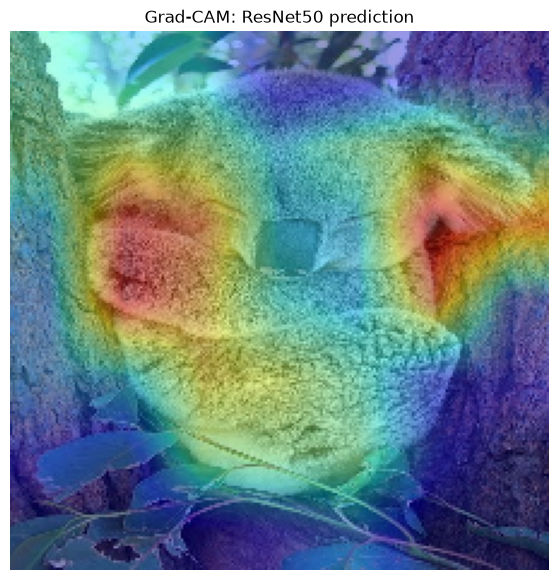

In [7]:
import tensorflow as tf
import keras
import numpy as np
import matplotlib.pyplot as plt

# ResNet50 was already loaded as 'model'
# x is the preprocessed elephant image

# Last convolutional feature layer of ResNet50
last_conv_layer = "conv5_block3_out"

# Model returning both feature maps and predictions
grad_model = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(last_conv_layer).output,
        model.output
    ]
)

# Calculate gradients for the predicted class
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(x)

    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

grads = tape.gradient(class_score, conv_outputs)

# Average gradients over spatial dimensions
weights = tf.reduce_mean(grads, axis=(0, 1, 2))

# Weighted combination of feature maps
heatmap = tf.reduce_sum(
    conv_outputs[0] * weights,
    axis=-1
)

# Keep positive contributions
heatmap = tf.maximum(heatmap, 0)
heatmap /= tf.reduce_max(heatmap) + 1e-8

# Resize heatmap to original image size
heatmap = tf.image.resize(
    heatmap[..., tf.newaxis], (224, 224)
).numpy().squeeze()

# Display
plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM: ResNet50 prediction")
plt.axis("off")
plt.show()

Below: Feature activation maps

In [10]:
import keras
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input
import numpy as np

model = VGG16(weights='imagenet', include_top=False)

img_path = 'img/koala.jpeg'
img = keras.utils.load_img(img_path, target_size=(224, 224))
x = keras.utils.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

features = model.predict(x)
activation = features[0].mean(axis=-1)   # shape (7, 7)



1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


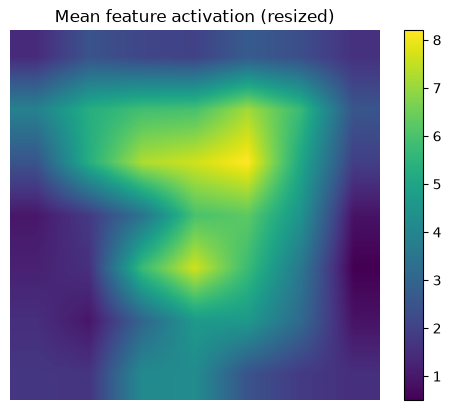

In [11]:
from tensorflow.image import resize

heatmap_big = resize(activation[..., np.newaxis], (224, 224)).numpy().squeeze()

plt.imshow(heatmap_big, cmap='viridis')
plt.colorbar()
plt.title("Mean feature activation (resized)")
plt.axis('off')
plt.show()


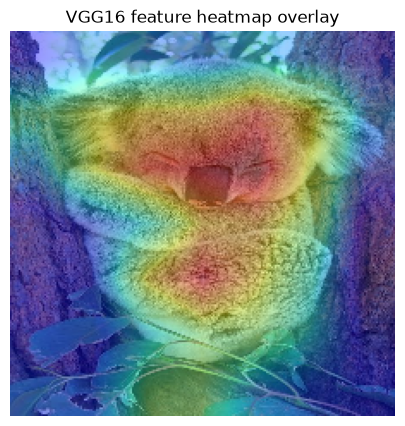

In [12]:
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.imshow(heatmap_big, cmap='jet', alpha=0.4)
plt.axis('off')
plt.title("VGG16 feature heatmap overlay")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


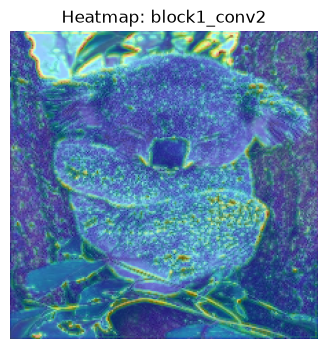

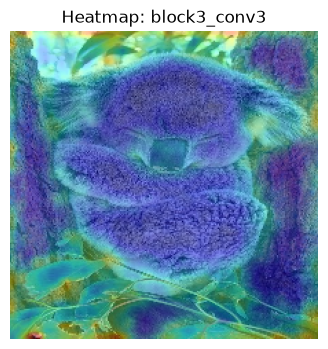

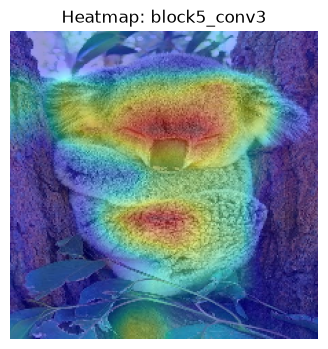

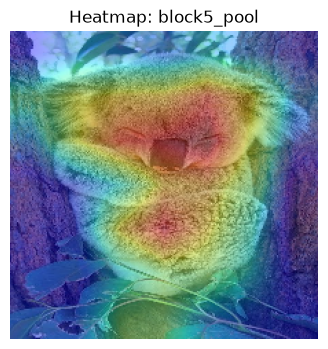

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.applications.vgg16 import VGG16, preprocess_input

# ---- settings ----
img_path = "img/koala.jpeg"
layer_names = ["block1_conv2", "block3_conv3", "block5_conv3", "block5_pool"]  # early / mid / deep

# ---- load model & build multi-output model ----
base_model = VGG16(weights="imagenet", include_top=False)
layer_outputs = [base_model.get_layer(name).output for name in layer_names]
vis_model = keras.Model(inputs=base_model.input, outputs=layer_outputs)

# ---- load and preprocess image ----
img = keras.utils.load_img(img_path, target_size=(224, 224))
img_disp = np.array(img)                              # for plotting
x = keras.utils.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# ---- get activations for selected layers ----
activations = vis_model.predict(x)   # list, one per layer

# ---- helper: make overlay heatmap for one activation ----
def overlay_heatmap_on_image(activation, img_disp, title):
    # activation: (H, W, C)
    act = activation.mean(axis=-1)                          # (H, W) mean over channels
    heatmap = tf.image.resize(act[..., np.newaxis], (224, 224)).numpy().squeeze()
    heatmap -= heatmap.min()
    heatmap /= (heatmap.max() + 1e-8)

    plt.figure(figsize=(4, 4))
    plt.imshow(img_disp)
    plt.imshow(heatmap, cmap="jet", alpha=0.4)
    plt.axis("off")
    plt.title(title)
    plt.show()

# ---- visualize all chosen layers ----
for name, act in zip(layer_names, activations):
    overlay_heatmap_on_image(act[0], img_disp, f"Heatmap: {name}")


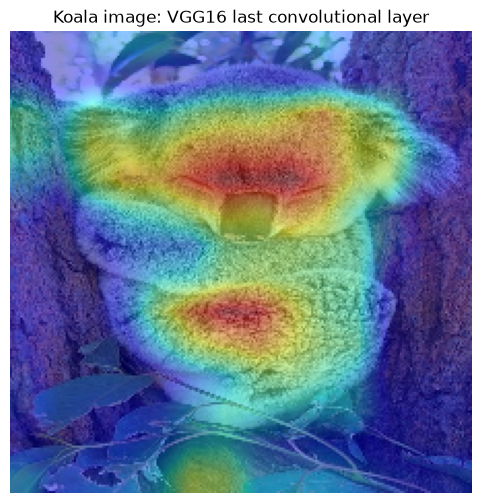

In [16]:
# Use the existing VGG16 base_model, preprocessed image x, and display image img_disp.
last_conv = base_model.get_layer("block5_conv3")
last_layer_model = keras.Model(inputs=base_model.input, outputs=last_conv.output)

last_features = last_layer_model.predict(x, verbose=0)[0]
activation_map = last_features.mean(axis=-1)

activation_map = tf.image.resize(
    activation_map[..., np.newaxis], img_disp.shape[:2]
).numpy().squeeze()
activation_map -= activation_map.min()
activation_map /= activation_map.max() + 1e-8

plt.figure(figsize=(6, 6))
plt.imshow(img_disp)
plt.imshow(activation_map, cmap="jet", alpha=0.45)
plt.title("Koala image: VGG16 last convolutional layer")
plt.axis("off")
plt.show()